### Mount Google Drive for Saving Results
Run this cell to connect your Google Drive. All results, traces, and visualizations will be saved directly to a folder named `Math500_Results` in your Drive.

In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Create a dedicated directory for the results
SAVE_DIR = '/content/drive/MyDrive/Math500_Results_INSTRUCT'
os.makedirs(SAVE_DIR, exist_ok=True)

# Change the current working directory so all subsequent saves/loads happen there
os.chdir(SAVE_DIR)
print(f"\nWorking directory changed to: {os.getcwd()}")
print("All results and traces will now be saved to your Google Drive.")

Mounted at /content/drive

Working directory changed to: /content/drive/MyDrive/Math500_Results
All results and traces will now be saved to your Google Drive.


### Step 1: Install Dependencies, Imports and Configurations

First, we will make sure we have the required libraries installed, import the necessary packages, and define our parameters (such as the target difficulty level, sample size, and models).

In [ ]:
#@title Installation and Setup
!pip install -q datasets transformers accelerate math_verify

import os
import random
import time
import json
import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer
from math_verify import parse, verify

# Configuration
MODELS = [
    "Qwen/Qwen2.5-1.5B-Instruct",
    "Qwen/Qwen2.5-3B-Instruct",
    "Qwen/Qwen2.5-7B-Instruct"
]

# Set LIMIT_PROBLEMS to an integer to evaluate a subset, or None to evaluate all 500 problems.
LIMIT_PROBLEMS = None

# Set seed for reproducibility
random.seed(21)
torch.manual_seed(42)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.1/209.1 kB 17.7 MB/s eta 0:00:00


### Step 2: Load and Filter the MATH-500 Dataset

We pull the `HuggingFaceH4/MATH-500` dataset, select the desired difficulty group, and sample 100 evaluation problems.

In [ ]:
print("Loading MATH-500 dataset...")
dataset = load_dataset("HuggingFaceH4/MATH-500", split="test")

# Convert to a list of problems
sampled_problems = list(dataset)

# Apply the limit if configured
if LIMIT_PROBLEMS is not None:
    sampled_problems = sampled_problems[:LIMIT_PROBLEMS]
    print(f"Loaded a subset of {len(sampled_problems)} problems across difficulty levels (LIMIT_PROBLEMS={LIMIT_PROBLEMS}).")
else:
    print(f"Loaded complete dataset with {len(sampled_problems)} problems across all difficulty levels.")

Loading MATH-500 dataset...


README.md:   0%|          | 0.00/412 [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/447k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/500 [00:00<?, ? examples/s]

Loaded complete dataset with 500 problems across all difficulty levels.


### Step 3: Define Prompt Rules and Extraction Logic

We set up two different prompt strategies:
- **Chain-of-Thought (CoT)**: Instructs the model to think step-by-step and write its final answer inside `\boxed{}`.
- **Direct (non-CoT)**: Instructs the model to output *only* the direct boxed answer.

In [ ]:
COT_SYSTEM_PROMPT = "You are a helpful assistant. Solve the math problem step-by-step, explaining your reasoning. Put your final answer inside \\boxed{answer}."
DIRECT_SYSTEM_PROMPT = "You are a helpful assistant. Give only your final numerical or algebraic answer inside \\boxed{answer} directly, without explaining your reasoning or showing any steps."

def build_prompt(problem, system_prompt):
    return [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": problem}
    ]

def extract_answer(text):
    stop_phrases = ["Difficulty Level:", "\nProblem:"]
    for phrase in stop_phrases:
        if phrase in text:
            text = text.split(phrase)[0]

    if "\\boxed{" not in text:
        return ""  # Return empty string if no boxed answer

    start_idx = text.find("\\boxed{") + len("\\boxed{")

    brace_count = 1
    for i in range(start_idx, len(text)):
        if text[i] == '{':
            brace_count += 1
        elif text[i] == '}':
            brace_count -= 1

        if brace_count == 0:
            return text[start_idx:i].strip()

    return ""  # Fallback if braces are malformed

def grade(pred, gold):
    gt = str(gold).strip()
    if pred == "":
        return False
    try:
        return bool(verify(parse(f"${gt}$"), parse(f"${pred}$")))
    except Exception:
        return pred.replace(" ", "").lower() == gt.replace(" ", "").lower()

### Step 4: Run Inference and Evaluate

We loop over each of our target models, performing generation for both **CoT** and **Direct** configurations. We measure the accuracy against ground truth as well as the average length of the generated outputs (to track token generation cost).

In [ ]:
import gc
import time
import json
import torch
import pandas as pd
from collections import defaultdict
from transformers import AutoModelForCausalLM, AutoTokenizer

# We will track detailed correct/total stats per model, per mode, and per difficulty level
detailed_results = []
raw_responses_log = []
BATCH_SIZE = 128  # Maximizing A100 parallelism

for model_name in MODELS:
    print(f"\nEvaluating model: {model_name}")

    # Initialize tokenizer and configure padding side for generation
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    # Load model fully onto GPU in bfloat16 for fast A100 Tensor Core computation
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        torch_dtype=torch.bfloat16 if torch.cuda.is_available() else torch.float32,
        device_map="auto"
    )

    for mode in ["CoT", "Direct"]:
        print(f"  Running {mode} mode in batches...")
        system_prompt = COT_SYSTEM_PROMPT if mode == "CoT" else DIRECT_SYSTEM_PROMPT

        start_time = time.time()

        # Temp dictionaries to aggregate stats by difficulty level for this model/mode run
        correct_by_lvl = defaultdict(int)
        total_by_lvl = defaultdict(int)
        tokens_by_lvl = defaultdict(int)

        # Process math problems in parallel batches
        for i in range(0, len(sampled_problems), BATCH_SIZE):
            batch_items = sampled_problems[i : i + BATCH_SIZE]
            batch_prompts = []

            for item in batch_items:
                messages = build_prompt(item["problem"], system_prompt)
                prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
                batch_prompts.append(prompt_text)

            # Tokenize batch
            inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True).to(model.device)
            input_len = inputs.input_ids.shape[1]

            max_new_tokens = 2048 if mode == "CoT" else 128

            with torch.no_grad():
                outputs = model.generate(
                    **inputs,
                    max_new_tokens=max_new_tokens,
                    do_sample=False,
                    temperature=None,
                    top_p=None
                )

            # Decode and evaluate batch responses
            for idx, (item, out_ids) in enumerate(zip(batch_items, outputs)):
                generated_ids = out_ids[input_len:]
                generated_text = tokenizer.decode(generated_ids, skip_special_tokens=True)

                gen_tokens_count = len(generated_ids)
                pred_ans = extract_answer(generated_text)
                ground_truth = item["answer"]
                lvl = str(item["level"])

                is_correct = 1 if grade(pred_ans, ground_truth) else 0

                correct_by_lvl[lvl] += is_correct
                total_by_lvl[lvl] += 1
                tokens_by_lvl[lvl] += gen_tokens_count

                # Store raw responses in detail
                raw_responses_log.append({
                    "model": model_name.split("/")[-1],
                    "mode": mode,
                    "difficulty_level": int(lvl),
                    "problem": item["problem"],
                    "ground_truth": ground_truth,
                    "raw_generated_response": generated_text,
                    "extracted_answer": pred_ans,
                    "is_correct": is_correct,
                    "generated_tokens_count": gen_tokens_count
                })

            global_idx = i + len(batch_items)
            print(f"    Progress: {global_idx}/{len(sampled_problems)} processed.")

        duration = time.time() - start_time

        # Log results partitioned by difficulty level
        for lvl in sorted(correct_by_lvl.keys(), key=int):
            lvl_correct = correct_by_lvl[lvl]
            lvl_total = total_by_lvl[lvl]
            lvl_tokens = tokens_by_lvl[lvl]

            lvl_accuracy = (lvl_correct / lvl_total) * 100 if lvl_total > 0 else 0
            lvl_avg_tokens = lvl_tokens / lvl_total if lvl_total > 0 else 0

            detailed_results.append({
                "Model": model_name.split("/")[-1],
                "Mode": mode,
                "Difficulty_Level": lvl,
                "Correct": lvl_correct,
                "Total": lvl_total,
                "Accuracy": round(lvl_accuracy, 2),
                "Avg_Tokens": round(lvl_avg_tokens, 1),
                "Duration_Sec": round(duration, 2)
            })

    # Release memory for the next model
    del model
    del tokenizer
    gc.collect()
    torch.cuda.empty_cache()
    time.sleep(1)

# Save the aggregated results to JSON and CSV
with open("math500_evaluation_results.json", "w") as f:
    json.dump(detailed_results, f, indent=4)

# Save the raw responses log to JSON
with open("math500_raw_responses.json", "w") as f:
    json.dump(raw_responses_log, f, indent=4)

df_results = pd.DataFrame(detailed_results)
df_results.to_csv("math500_evaluation_results.csv", index=False)
print("\nEvaluation complete! Results successfully saved to math500_evaluation_results.csv, math500_evaluation_results.json, and math500_raw_responses.json.")


Evaluating model: Qwen/Qwen2.5-1.5B-Instruct


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (24 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

  Running CoT mode in batches...
    Progress: 128/500 processed.
    Progress: 256/500 processed.
    Progress: 384/500 processed.
    Progress: 500/500 processed.
  Running Direct mode in batches...
    Progress: 128/500 processed.
    Progress: 256/500 processed.
    Progress: 384/500 processed.
    Progress: 500/500 processed.

Evaluation complete! Results successfully saved to math500_evaluation_results.csv, math500_evaluation_results.json, and math500_raw_responses.json.


### Step 5: Visualize Accuracy vs. Token Generation Cost

Finally, we compile our results into a Pandas DataFrame and plot a comparative dual-axis visualization showing both accuracy and token consumption side-by-side.


--- Detailed Evaluation Summary (By Difficulty Level) ---


,Model,Mode,Difficulty_Level,Correct,Total,Accuracy,Avg_Tokens,Duration_Sec
0,Qwen2.5-1.5B-Instruct,CoT,1,36,43,83.72,1024.0,316.42
1,Qwen2.5-1.5B-Instruct,CoT,2,51,90,56.67,1024.0,316.42
2,Qwen2.5-1.5B-Instruct,CoT,3,53,105,50.48,1024.0,316.42
3,Qwen2.5-1.5B-Instruct,CoT,4,47,128,36.72,1024.0,316.42
4,Qwen2.5-1.5B-Instruct,CoT,5,25,134,18.66,1024.0,316.42
5,Qwen2.5-1.5B-Instruct,Direct,1,15,43,34.88,128.0,32.24
6,Qwen2.5-1.5B-Instruct,Direct,2,20,90,22.22,128.0,32.24
7,Qwen2.5-1.5B-Instruct,Direct,3,12,105,11.43,128.0,32.24
8,Qwen2.5-1.5B-Instruct,Direct,4,6,128,4.69,128.0,32.24
9,Qwen2.5-1.5B-Instruct,Direct,5,0,134,0.00,128.0,32.24


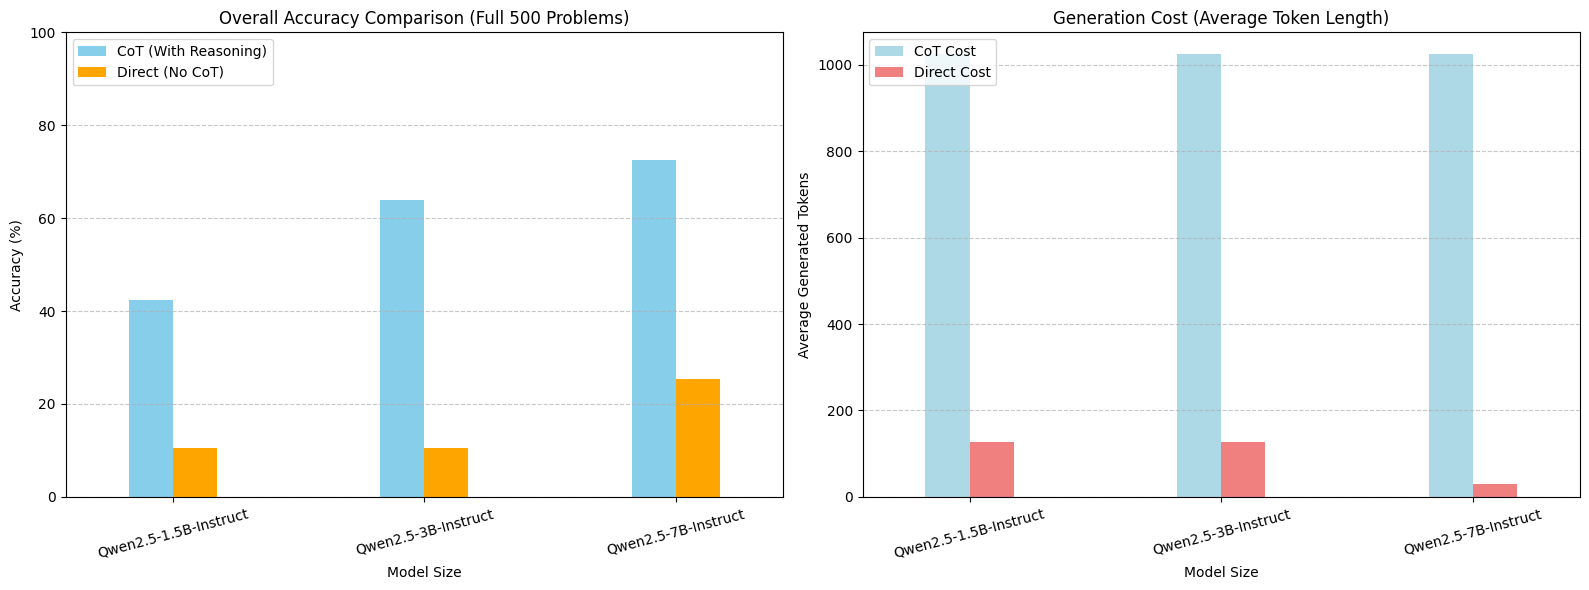

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load results from the exported CSV
df = pd.read_csv("math500_evaluation_results.csv")

print("\n--- Detailed Evaluation Summary (By Difficulty Level) ---")
display(df)

# Aggregate results globally across all levels for overall plotting comparison
df_overall = df.groupby(["Model", "Mode"]).agg({
    "Correct": "sum",
    "Total": "sum",
    "Avg_Tokens": "mean"
}).reset_index()
df_overall["Accuracy"] = (df_overall["Correct"] / df_overall["Total"]) * 100

# Create two separate subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Accuracy Comparison
df_pivot_acc = df_overall.pivot(index="Model", columns="Mode", values="Accuracy")
df_pivot_acc.plot(kind="bar", ax=ax1, width=0.35, color=["skyblue", "orange"])
ax1.set_ylabel("Accuracy (%)")
ax1.set_xlabel("Model Size")
ax1.set_title("Overall Accuracy Comparison (Full 500 Problems)")
ax1.set_ylim(0, 100)
ax1.grid(axis='y', linestyle='--', alpha=0.7)
ax1.legend(["CoT (With Reasoning)", "Direct (No CoT)"], loc="upper left")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=15)

# Plot 2: Token Cost Comparison
df_pivot_cost = df_overall.pivot(index="Model", columns="Mode", values="Avg_Tokens")
df_pivot_cost.plot(kind="bar", ax=ax2, width=0.35, color=["lightblue", "lightcoral"])
ax2.set_ylabel("Average Generated Tokens")
ax2.set_xlabel("Model Size")
ax2.set_title("Generation Cost (Average Token Length)")
ax2.grid(axis='y', linestyle='--', alpha=0.7)
ax2.legend(["CoT Cost", "Direct Cost"], loc="upper left")
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=15)

plt.tight_layout()
plt.show()

### Step 6: Detailed Plots by Difficulty Level and Model Size

Below, we break down the results further to visualize how each model size performs across difficulty levels (1 to 5) for both Chain-of-Thought (CoT) and Direct reasoning modes.

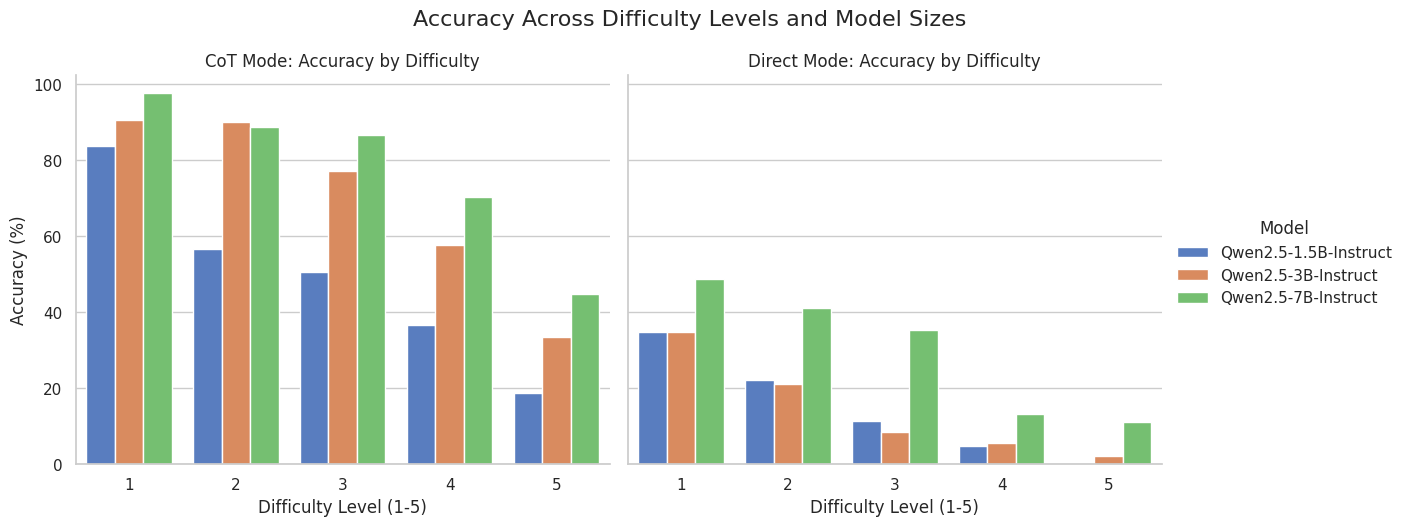

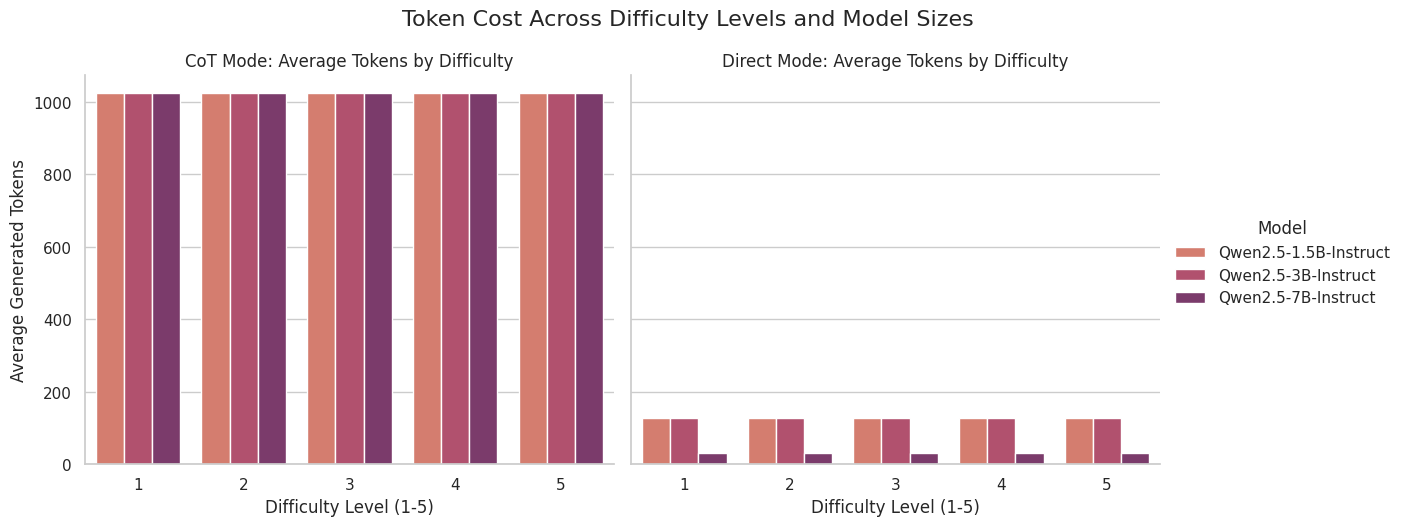

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read the saved CSV results
df = pd.read_csv("math500_evaluation_results.csv")

# Ensure difficulty level is sorted correctly as integer
df["Difficulty_Level"] = df["Difficulty_Level"].astype(int)
df = df.sort_values(by=["Difficulty_Level", "Model"])

# Set the plotting style
sns.set_theme(style="whitegrid")

# --- Plot 1: Accuracy by Difficulty Level and Model Size (Facet by Mode) ---
g = sns.catplot(
    data=df,
    x="Difficulty_Level",
    y="Accuracy",
    hue="Model",
    col="Mode",
    kind="bar",
    height=5,
    aspect=1.2,
    palette="muted"
)
g.set_axis_labels("Difficulty Level (1-5)", "Accuracy (%)")
g.set_titles("{col_name} Mode: Accuracy by Difficulty")
g.fig.suptitle("Accuracy Across Difficulty Levels and Model Sizes", y=1.05, fontsize=16)
plt.show()

# --- Plot 2: Token Cost by Difficulty Level and Model Size (Facet by Mode) ---
h = sns.catplot(
    data=df,
    x="Difficulty_Level",
    y="Avg_Tokens",
    hue="Model",
    col="Mode",
    kind="bar",
    height=5,
    aspect=1.2,
    palette="flare"
)
h.set_axis_labels("Difficulty Level (1-5)", "Average Generated Tokens")
h.set_titles("{col_name} Mode: Average Tokens by Difficulty")
h.fig.suptitle("Token Cost Across Difficulty Levels and Model Sizes", y=1.05, fontsize=16)
plt.show()

### Step 7: Heatmap Visualizations

To complement the bar charts, we will visualize the exact values using heatmaps. We show both **Accuracy (%)** and **Average Tokens** indexed by Model Size and Difficulty Level for both reasoning modes.

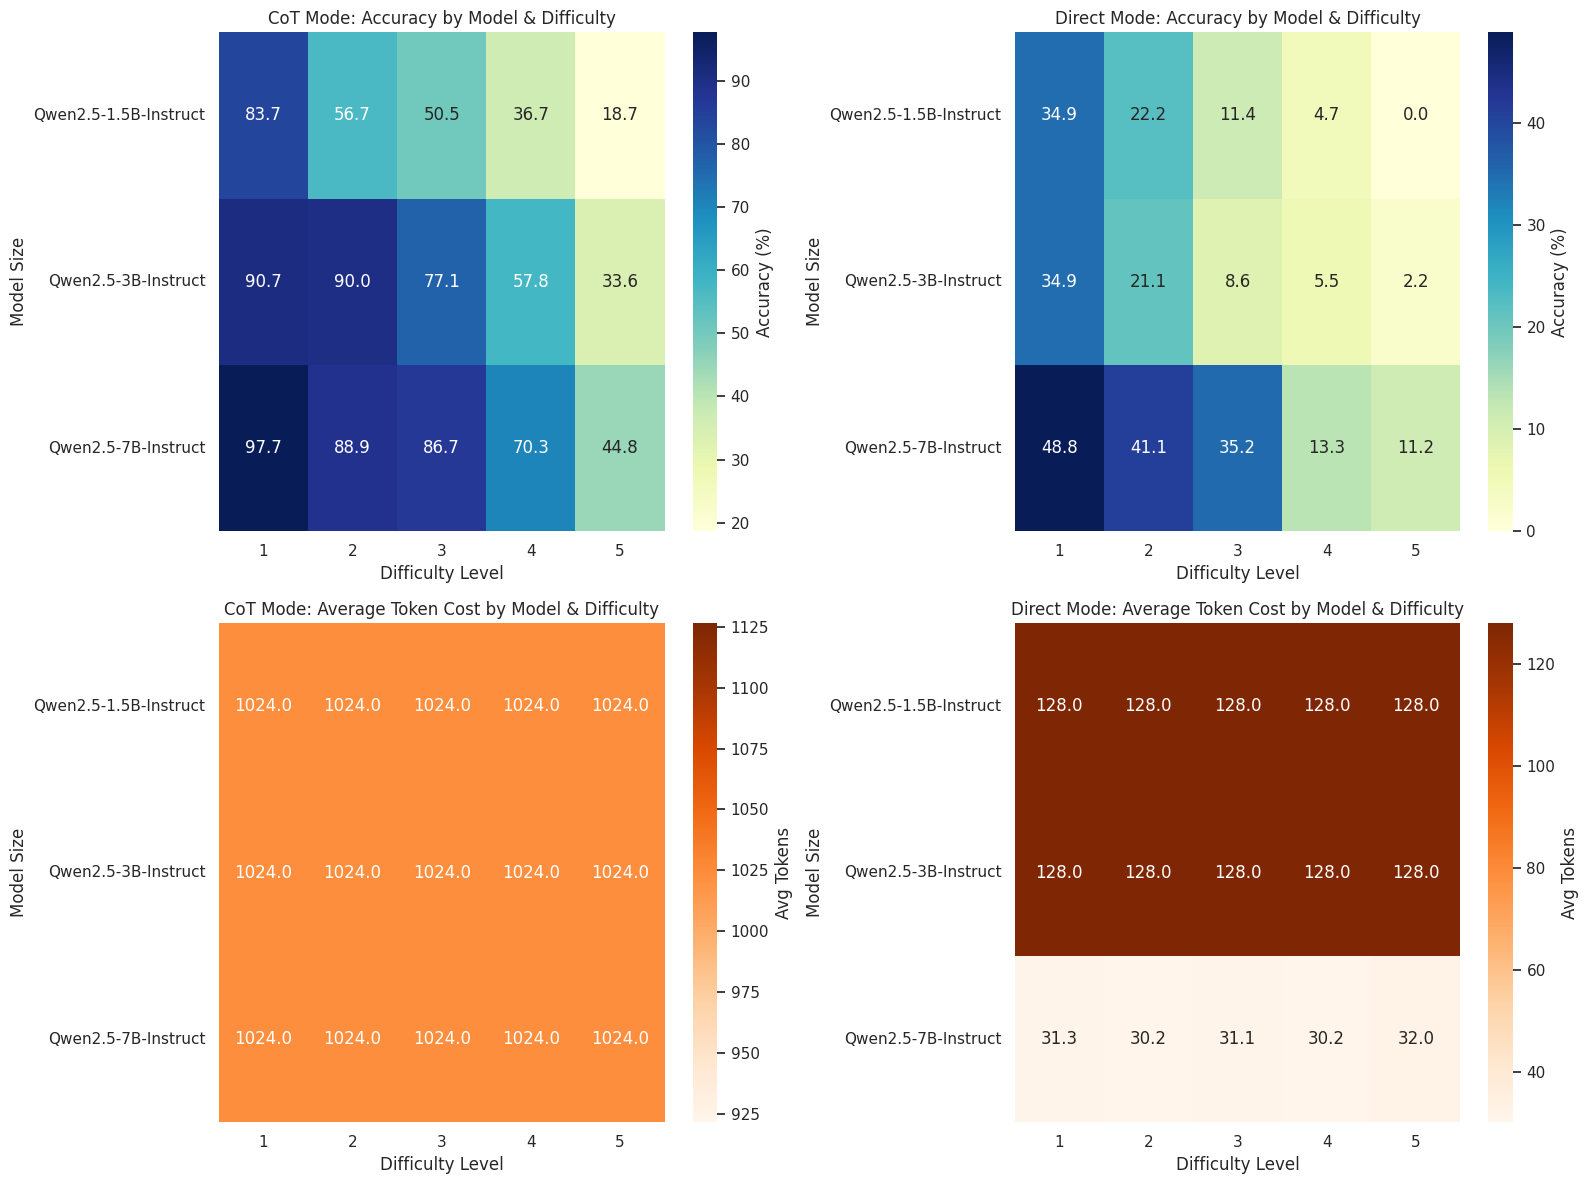

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read saved results
df = pd.read_csv("math500_evaluation_results.csv")
df["Difficulty_Level"] = df["Difficulty_Level"].astype(int)

# Setup figure for heatmaps
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Filter modes
df_cot = df[df["Mode"] == "CoT"]
df_dir = df[df["Mode"] == "Direct"]

# Create Pivot Tables
# 1. Accuracy pivots
pivot_acc_cot = df_cot.pivot(index="Model", columns="Difficulty_Level", values="Accuracy")
pivot_acc_dir = df_dir.pivot(index="Model", columns="Difficulty_Level", values="Accuracy")

# 2. Avg Tokens pivots
pivot_tok_cot = df_cot.pivot(index="Model", columns="Difficulty_Level", values="Avg_Tokens")
pivot_tok_dir = df_dir.pivot(index="Model", columns="Difficulty_Level", values="Avg_Tokens")

# Heatmap 1: CoT Accuracy
sns.heatmap(pivot_acc_cot, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[0, 0], cbar_kws={'label': 'Accuracy (%)'})
axes[0, 0].set_title("CoT Mode: Accuracy by Model & Difficulty")
axes[0, 0].set_xlabel("Difficulty Level")
axes[0, 0].set_ylabel("Model Size")

# Heatmap 2: Direct Accuracy
sns.heatmap(pivot_acc_dir, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[0, 1], cbar_kws={'label': 'Accuracy (%)'})
axes[0, 1].set_title("Direct Mode: Accuracy by Model & Difficulty")
axes[0, 1].set_xlabel("Difficulty Level")
axes[0, 1].set_ylabel("Model Size")

# Heatmap 3: CoT Avg Tokens
sns.heatmap(pivot_tok_cot, annot=True, fmt=".1f", cmap="Oranges", ax=axes[1, 0], cbar_kws={'label': 'Avg Tokens'})
axes[1, 0].set_title("CoT Mode: Average Token Cost by Model & Difficulty")
axes[1, 0].set_xlabel("Difficulty Level")
axes[1, 0].set_ylabel("Model Size")

# Heatmap 4: Direct Avg Tokens
sns.heatmap(pivot_tok_dir, annot=True, fmt=".1f", cmap="Oranges", ax=axes[1, 1], cbar_kws={'label': 'Avg Tokens'})
axes[1, 1].set_title("Direct Mode: Average Token Cost by Model & Difficulty")
axes[1, 1].set_xlabel("Difficulty Level")
axes[1, 1].set_ylabel("Model Size")

plt.tight_layout()
plt.show()